# 06 · Choose an evidence source

Does a question need document retrieval, a graph, SQL or long context?

Compare long-context and retrieval for manual questions using matched budgets. For structured inventory questions, use a semantic view with read-only parameterised SQL. Compare graph traversal on entity-link questions. Report within-family results and one routed aggregate.

**Measures** — Citation support, exact numeric answers, routing errors, coverage and input budget by question family.

**Evidence** — Evidence router with four case types and a retained source per answer.

**Runtime** — CPU data paths, T4 generation. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 6

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Choose an evidence source

The operator asks “What is its maximum temperature?” after viewing fan F-250.
You have the manual, an inventory view and an equipment graph. Which source
can support the temperature? What changes if the saved manual revision is old?
[Read Lesson 6](https://docs.recohut.com/courses/advanced-ai-systems-engineering/2-build-the-evidence-layer/06-choose-an-evidence-source).

The notebook tests document ordering on the same requests with the same model.
It also reads exact inspection dates from a fixed SQLite view and combines a
row and a graph edge when the operator asks which system supports the asset.

In [6]:
import re
from collections import defaultdict
from statistics import median
from time import perf_counter

EVIDENCE_TOKEN_BUDGET = 112
OUTPUT_TOKEN_BUDGET = 100
MANUAL_BATCH_SIZE = 4
MANUAL_METHODS = ("Corpus prefix", "Exact ID first", "All tenant manuals")
ROUTED_METHODS = ("Routed · corpus prefix", "Routed · exact ID first", "Routed · all manuals")
ROUTE_BY_SLICE = {
    "manual": "manual",
    "numeric": "SQL",
    "multi_source": "graph + SQL",
    "ambiguity": "clarify",
    "boundary": "deny",
    "follow_up": "manual",
}
ASSET_ID = re.compile(r"\b[PFV]-\d+\b", re.IGNORECASE)

manuals_by_tenant = defaultdict(list)
edges_by_tenant = defaultdict(dict)
asset_index = {}
for equipment in assets("dev"):
    tenant = equipment["tenant"]
    asset_index[tenant, equipment["asset"]] = equipment
    edges_by_tenant[tenant][equipment["asset"]] = {
        "target": equipment["linked"], "type": "supported_by", "evidence": equipment["graph_id"]
    }
for document in corpus("dev"):
    if document["source"] == "manual":
        manuals_by_tenant[document["tenant"]].append(document)


def no_answer(decision):
    return {"decision": decision, "value": "", "evidence": []}


def select_route(question, role, tenant, previous_asset="", previous_version=""):
    """Resolve the trusted scope and one current equipment ID before lookup."""
    if role != "operator" or tenant not in manuals_by_tenant:
        return "deny", None
    matches = {match.upper() for match in ASSET_ID.findall(question)}
    if len(matches) > 1:
        return "clarify", None
    asset_id = next(iter(matches), previous_asset)
    equipment = asset_index.get((tenant, asset_id))
    if equipment is None or (not matches and previous_version != equipment["version"]):
        return "clarify", None
    request = question.casefold()
    if "support" in request:
        return ("graph + SQL" if "inspect" in request else "graph"), equipment
    if "inspect" in request:
        return "SQL", equipment
    if any(term in request for term in ("temperature", "thermal limit", "how hot")):
        return "manual", equipment
    return "clarify", None


def structured_answer(route, equipment, role, tenant):
    if route in {"deny", "clarify"}:
        return no_answer(route), {}
    if role != "operator" or equipment["tenant"] != tenant:
        return no_answer("deny"), {}
    asset_id = equipment["asset"]
    inventory = read_inventory(asset_id, tenant, role) if route in {"SQL", "graph + SQL"} else None
    relation = edges_by_tenant[tenant].get(asset_id) if route in {"graph", "graph + SQL"} else None
    if ((route in {"SQL", "graph + SQL"} and not inventory)
            or (route in {"graph", "graph + SQL"} and not relation)):
        return no_answer("clarify"), {}

    reads = {}
    values, evidence = [], []
    if inventory:
        reads["inventory"] = {"row": inventory, "evidence": equipment["inventory_id"]}
        values.append(inventory["inspection"])
        evidence.append(equipment["inventory_id"])
    if relation:
        reads["graph"] = relation
        values.append(relation["target"])
        evidence.append(relation["evidence"])
    return {"decision": "answer", "value": " | ".join(values), "evidence": evidence}, reads

## Does the desk have a current reference?

Keep the request and signed-in role fixed. Before reading the source,
predict which route the desk should choose if the saved F-250 revision
differs from the current one. The inventory view supplies exact dates.
The graph supplies one typed edge. Both reads use the trusted tenant.

In [7]:
def route_case(case):
    return select_route(case["question"], case["role"], case["tenant"],
                        case["previous_asset"], case["previous_version"])


def expected_answer(case):
    return {field: case[field] for field in ("decision", "value", "evidence")}


dev_cases = [case for case in cases("dev") if case["variant"] in {0, 3}]
assert len(dev_cases) == 2 * len(asset_index)
assert {case["slice"] for case in dev_cases} == set(SLICES)
assert SPLIT_MANIFEST["dev"]["sha256"] == digest(cases("dev"))
opening_case = next(case for case in dev_cases if case["id"] == "F250-00")
opening_route, opening_equipment = route_case(opening_case)
stale_revision = "r2"
assert opening_equipment["version"] != stale_revision
stale_case = {**opening_case, "previous_version": stale_revision}
stale_route, stale_equipment = route_case(stale_case)
opening_manual = next(doc for doc in manuals_by_tenant[opening_case["tenant"]]
                      if doc["id"] == opening_equipment["manual_id"])
assert opening_route == "manual"
assert (stale_route, stale_equipment) == ("clarify", None)
opening = {
    "case_id": opening_case["id"], "question": opening_case["question"],
    "role": opening_case["role"], "tenant": opening_case["tenant"],
    "asset": opening_case["previous_asset"], "manual": opening_manual,
    "current": {"revision": opening_case["previous_version"], "route": opening_route,
                "expected": expected_answer(opening_case)},
    "stale": {"revision": stale_revision, "route": stale_route, "expected": no_answer("clarify")},
}

multi_case = next(case for case in dev_cases if case["slice"] == "multi_source")
multi_route, multi_equipment = route_case(multi_case)
multi_answer, multi_sources = structured_answer(multi_route, multi_equipment,
                                               multi_case["role"], multi_case["tenant"])
assert score_answer(multi_case, multi_answer) == 1
graph_route, graph_equipment = select_route("Which system supports F-250?", "operator", opening_case["tenant"])
assert graph_route == "graph"
graph_answer, graph_sources = structured_answer(graph_route, graph_equipment, "operator", opening_case["tenant"])
assert graph_answer == {"decision": "answer", "value": opening_equipment["linked"],
                        "evidence": [opening_equipment["graph_id"]]}
assert set(graph_sources) == {"graph"}
assert route_case(next(case for case in dev_cases if case["slice"] == "boundary")) == ("deny", None)
other_tenant = next(tenant for tenant in manuals_by_tenant if tenant != opening_case["tenant"])
assert select_route("What is the maximum temperature for F-250?", "operator", other_tenant) == ("clarify", None)
assert structured_answer(multi_route, multi_equipment, "guest", multi_case["tenant"])[0] == no_answer("deny")
print("One changed field", opening)
print("One request needs two sources", {"question": multi_case["question"], "sources": multi_sources,
                                      "expected": expected_answer(multi_case), "returned": multi_answer})

One changed field {'case_id': 'F250-00', 'question': 'What is its maximum temperature?', 'role': 'operator', 'tenant': 'north-yard', 'asset': 'F-250', 'manual': {'id': 'manual-F-250-r3', 'source': 'manual', 'text': 'Equipment manual for F-250 (revision r3). Maximum operating temperature: 101 C. Known fault: filter blockage. The supporting system is S-650. Maintenance owner: controls.', 'tenant': 'north-yard', 'family': 'F250'}, 'current': {'revision': 'r3', 'route': 'manual', 'expected': {'decision': 'answer', 'value': '101', 'evidence': ['manual-F-250-r3']}}, 'stale': {'revision': 'r2', 'route': 'clarify', 'expected': {'decision': 'clarify', 'value': '', 'evidence': []}}}
One request needs two sources {'question': 'Give the last inspection date and supporting system for F-220.', 'sources': {'inventory': {'row': {'asset': 'F-220', 'tenant': 'north-yard', 'inspection': '2025-05-05', 'version': 'r3'}, 'evidence': 'inventory-F-220-r3'}, 'graph': {'target': 'S-620', 'type': 'supported_by',

## Which manual survives the token budget?

“Corpus prefix” keeps the first evidence tokens in corpus order. “Exact ID
first” puts the verified asset’s current manual first and applies the same
ceiling. This tests the effect of ordering. “All tenant manuals” keeps the
whole scoped corpus and exposes the cost of removing that ceiling.

Look for both the manual ID and its temperature line together. A source ID on
its own can survive clipping after the relevant value has been lost.

In [8]:
def build_manual_context(equipment, method, tokenizer):
    primary = equipment["manual_id"]
    entries = manuals_by_tenant[equipment["tenant"]]
    if method == "Exact ID first":
        entries = sorted(entries, key=lambda doc: doc["id"] != primary)
    context = "\n".join(f'[{doc["id"]}] {doc["text"]}' for doc in entries)
    all_ids = tokenizer.encode(context, add_special_tokens=False)
    visible_ids = all_ids if method == "All tenant manuals" else all_ids[:EVIDENCE_TOKEN_BUDGET]
    visible = tokenizer.decode(visible_ids)
    support = f'[{primary}] {manual_text(equipment).partition(" Known fault:")[0]}'
    return {
        "context": visible,
        "evidence_tokens": len(visible_ids),
        "discarded_tokens": len(all_ids) - len(visible_ids),
        "support_visible": support in visible,
    }


def input_token_count(tokenizer, prompt):
    rendered = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True
    )
    return len(tokenizer.encode(rendered, add_special_tokens=False))


def scored_record(case, method, route, response, context=None, raw=None, **details):
    expected = expected_answer(case)
    answer_evidence = response.get("evidence")
    covered = response.get("decision") == "answer"
    cites_expected = (covered and isinstance(answer_evidence, list)
                     and all(isinstance(item, str) for item in answer_evidence)
                     and sorted(answer_evidence) == sorted(expected["evidence"]))
    answer_value = response.get("value")
    exact_value = isinstance(answer_value, str) and answer_value.strip() == expected["value"]
    strict = score_answer(case, response)
    if strict:
        outcome = "Pass"
    elif raw is not None and not response:
        outcome = "No usable JSON object"
    elif response.get("decision") != expected["decision"]:
        outcome = "Wrong decision"
    elif not exact_value:
        outcome = "Wrong value"
    else:
        outcome = "Wrong evidence"
    return {
        "case_id": case["id"], "family": case["family"], "slice": case["slice"],
        "question": case["question"], "role": case["role"], "tenant": case["tenant"],
        "previous_asset": case["previous_asset"], "previous_version": case["previous_version"],
        "method": method, "expected_route": ROUTE_BY_SLICE[case["slice"]], "route": route,
        "expected": expected, "response": response, "raw": raw,
        "route_error": route != ROUTE_BY_SLICE[case["slice"]], "covered": covered,
        "citation_support": cites_expected if expected["decision"] == "answer" else None,
        "exact_value": exact_value if expected["decision"] == "answer" else None,
        "strict_pass": strict, "outcome": outcome,
        **(context or {}), **details,
    }


manual_cases, cpu_records, structured_ablation = [], [], []
for case in dev_cases:
    route, equipment = route_case(case)
    if route == "manual":
        manual_cases.append((case, equipment))
        continue
    answer, sources = structured_answer(route, equipment, case["role"], case["tenant"])
    cpu_records.append(scored_record(case, "Shared structured routes", route, answer, sources=sources))
    if route == "graph + SQL":
        for method in ("SQL", "graph", "graph + SQL"):
            output, reads = structured_answer(method, equipment, case["role"], case["tenant"])
            structured_ablation.append(scored_record(case, method, method, output, sources=reads))

assert len(manual_cases) + len(cpu_records) == len(dev_cases)

## Compare answer quality, generation time and GPU memory

The manual arms use the same frozen model, prompts apart from the supplied
evidence, batch membership and generation cap. An excluded warm-up runs
before timing. Each timed batch includes tokenisation, generation and
decoding. Peak allocated GPU memory includes the loaded model. Prompt
tokens count the unpadded rendered input, and output-text token counts
re-tokenise the decoded reply without special tokens.

In [9]:
manual_records, batch_timings, model_load_s = [], [], None
if not COURSE_SMOKE:
    started = perf_counter()
    tokenizer, model = load_text()
    sync()
    model_load_s = perf_counter() - started

    prepared = {}
    for method in MANUAL_METHODS:
        rows = []
        for case, equipment in manual_cases:
            context = build_manual_context(equipment, method, tokenizer)
            prompt = answer_prompt(case, context["context"])
            rows.append((case, context, prompt, input_token_count(tokenizer, prompt)))
        prepared[method] = rows

    assert all(row[1]["support_visible"] for row in prepared["Exact ID first"])
    assert all(row[1]["support_visible"] for row in prepared["All tenant manuals"])
    assert all(
        a[1]["evidence_tokens"] == b[1]["evidence_tokens"]
        for a, b in zip(prepared["Corpus prefix"], prepared["Exact ID first"])
    )

    warmup = [row[2] for row in prepared["All tenant manuals"][:MANUAL_BATCH_SIZE]]
    generate(tokenizer, model, warmup, max_new_tokens=8)
    sync()
    for start in range(0, len(manual_cases), MANUAL_BATCH_SIZE):
        # Alternate ordering so a fixed arm does not always start each group.
        methods = MANUAL_METHODS if (start // MANUAL_BATCH_SIZE) % 2 == 0 else MANUAL_METHODS[::-1]
        for method in methods:
            batch = prepared[method][start:start + MANUAL_BATCH_SIZE]
            if torch.cuda.is_available():
                torch.cuda.reset_peak_memory_stats()
            sync()
            started = perf_counter()
            outputs = generate(tokenizer, model, [row[2] for row in batch], max_new_tokens=OUTPUT_TOKEN_BUDGET)
            sync()
            wall_ms = (perf_counter() - started) * 1000
            assert len(outputs) == len(batch)
            output_counts = [len(tokenizer.encode(raw, add_special_tokens=False)) for raw in outputs]
            batch_timings.append({
                "method": method, "case_ids": [row[0]["id"] for row in batch], "wall_ms": wall_ms,
                "peak_allocated_bytes": torch.cuda.max_memory_allocated() if torch.cuda.is_available() else None,
                "input_tokens": sum(row[3] for row in batch), "output_text_tokens": sum(output_counts),
            })
            for (case, context, _, prompt_tokens), raw, output_tokens in zip(batch, outputs, output_counts):
                manual_records.append(scored_record(case, method, "manual", decode_answer(raw),
                    context=context, raw=raw, prompt_tokens=prompt_tokens, output_text_tokens=output_tokens))

    assert len(manual_records) == len(MANUAL_METHODS) * len(manual_cases)
else:
    # A reversible character tokenizer makes clipping observable offline.
    # Its fixture counts do not enter model evidence or time tables.
    class FixtureTokenizer:
        def encode(self, text, add_special_tokens=False):
            return list(text)

        def decode(self, tokens):
            return "".join(tokens)

    fixture_tokenizer = FixtureTokenizer()
    source = build_manual_context(opening_equipment, "Exact ID first", fixture_tokenizer)
    baseline = build_manual_context(opening_equipment, "Corpus prefix", fixture_tokenizer)
    assert source["support_visible"] and not baseline["support_visible"]
    assert source["evidence_tokens"] == baseline["evidence_tokens"]
    assert build_manual_context(opening_equipment, "All tenant manuals", fixture_tokenizer)["discarded_tokens"] == 0

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


## Did each source answer the question it was asked?

The routed arms share the deterministic SQL, graph, clarification and denial
outcomes. Only the manual context policy changes. Compare manual arms on
their common requests and routed arms on the complete development sample.
The paired intervals use equipment families, so rewordings of a ticket stay
together in each draw. Report the ablation separately because it has only
the families whose questions require two sources.

Evidence comparison {'mode': 'full', 'settings': {'evidence_token_ceiling': 112, 'output_token_cap': 100, 'batch_size': 4, 'variants': [0, 3], 'bootstrap_draws': 1500, 'development_sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf'}, 'cohorts': {'development_cases': 24, 'development_families': 12, 'manual_cases': 8, 'structured_cases': 16}, 'outcomes': [{'method': 'Shared structured routes', 'slice': 'numeric', 'cases': 4, 'family_count': 2, 'answerable_cases': 4, 'covered': 4, 'route_errors': 0, 'route_accuracy': 1.0, 'citation_matches': 4, 'exact_values': 4, 'strict_passes': 4, 'strict_pass_rate': 1.0, 'outcomes': {'Pass': 4}}, {'method': 'Shared structured routes', 'slice': 'all', 'cases': 16, 'family_count': 8, 'answerable_cases': 8, 'covered': 8, 'route_errors': 0, 'route_accuracy': 1.0, 'citation_matches': 8, 'exact_values': 8, 'strict_passes': 16, 'strict_pass_rate': 1.0, 'outcomes': {'Pass': 16}}, {'method': 'Shared structured routes', 'slice': 'multi_s

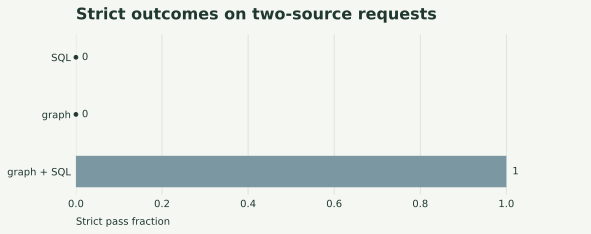

In [10]:
def summarise(group):
    answerable = [row for row in group if row["expected"]["decision"] == "answer"]
    failures = defaultdict(int)
    for row in group:
        failures[row["outcome"]] += 1
    return {
        "cases": len(group), "family_count": len({row["family"] for row in group}),
        "answerable_cases": len(answerable), "covered": sum(row["covered"] for row in group),
        "route_errors": sum(row["route_error"] for row in group),
        "route_accuracy": sum(not row["route_error"] for row in group) / len(group),
        "citation_matches": sum(row["citation_support"] for row in answerable),
        "exact_values": sum(row["exact_value"] for row in answerable),
        "strict_passes": sum(row["strict_pass"] for row in group),
        "strict_pass_rate": sum(row["strict_pass"] for row in group) / len(group),
        "outcomes": dict(failures),
    }


def grouped_outcomes(records):
    groups = defaultdict(list)
    for row in records:
        groups[row["method"], row["slice"]].append(row)
        groups[row["method"], "all"].append(row)
    return [
        {"method": method, "slice": question_slice, **summarise(group)}
        for (method, question_slice), group in groups.items()
    ]


def compare_paired(name, candidate, incumbent, rows):
    def outcomes(method):
        return {row["case_id"]: row["strict_pass"] for row in rows if row["method"] == method}

    new, old = outcomes(candidate), outcomes(incumbent)
    assert new.keys() == old.keys() and new
    matching = [case for case in dev_cases if case["id"] in new]
    return {
        "cohort": name, "candidate": candidate, "incumbent": incumbent,
        "wins": sum(new[key] > old[key] for key in new), "losses": sum(new[key] < old[key] for key in new),
        **paired_interval(matching, [new[case["id"]] for case in matching],
                          [old[case["id"]] for case in matching]),
    }


# The same observed non-manual outputs are re-used in each routed comparison.
routed_records = []
pairs = [compare_paired("Two-source requests", "graph + SQL", ablation, structured_ablation)
         for ablation in ("SQL", "graph")]
if manual_records:
    for manual_method, routed_method in zip(MANUAL_METHODS, ROUTED_METHODS):
        routed_records.extend(
            {**row, "method": routed_method}
            for row in [*cpu_records, *manual_records]
            if row["method"] in {"Shared structured routes", manual_method}
        )
    assert len(routed_records) == len(dev_cases) * len(ROUTED_METHODS)
    for method, routed_method in zip(MANUAL_METHODS[1:], ROUTED_METHODS[1:]):
        pairs += [
            compare_paired("Manual requests", method, MANUAL_METHODS[0], manual_records),
            compare_paired("All development requests", routed_method, ROUTED_METHODS[0], routed_records),
        ]

manual_costs = []
for method in MANUAL_METHODS:
    rows = [row for row in manual_records if row["method"] == method]
    timings = [row for row in batch_timings if row["method"] == method]
    if rows:
        peaks = [row["peak_allocated_bytes"] for row in timings if row["peak_allocated_bytes"] is not None]
        manual_costs.append({
            "method": method, "cases": len(rows), "batches": len(timings),
            "support_visible": sum(row["support_visible"] for row in rows),
            "evidence_tokens_median": median(row["evidence_tokens"] for row in rows),
            "discarded_tokens_median": median(row["discarded_tokens"] for row in rows),
            "prompt_tokens_median": median(row["prompt_tokens"] for row in rows),
            "output_text_tokens_median": median(row["output_text_tokens"] for row in rows),
            "batch_wall_ms_median": median(row["wall_ms"] for row in timings),
            "peak_allocated_bytes": max(peaks) if peaks else None,
        })

outcomes = grouped_outcomes([*cpu_records, *manual_records, *routed_records])
structured_summary = [{"method": method, **summarise([row for row in structured_ablation if row["method"] == method])}
                      for method in ("SQL", "graph", "graph + SQL")]
summary = {
    "mode": "smoke" if COURSE_SMOKE else "full", "settings": {
        "evidence_token_ceiling": EVIDENCE_TOKEN_BUDGET, "output_token_cap": OUTPUT_TOKEN_BUDGET,
        "batch_size": MANUAL_BATCH_SIZE, "variants": [0, 3], "bootstrap_draws": 1500,
        "development_sha256": SPLIT_MANIFEST["dev"]["sha256"],
    },
    "cohorts": {"development_cases": len(dev_cases), "development_families": len(asset_index),
                "manual_cases": len(manual_cases), "structured_cases": len(cpu_records)},
    "outcomes": outcomes, "structured_ablation": structured_summary, "paired_strict": pairs,
    "manual_costs": manual_costs, "model_load_s": model_load_s,
}
print("Evidence comparison", summary)
print("Opening ticket, observed manual outputs",
      [row for row in manual_records if row["case_id"] == opening_case["id"]])
first_miss = next((row for row in manual_records if not row["strict_pass"]), None)
if first_miss is not None:
    print("First recorded manual miss", first_miss)
save("summary", summary)
save("records", {"opening": opening, "decisions": [*cpu_records, *manual_records, *routed_records],
                 "batch_timings": batch_timings})
save("structured-ablation", structured_ablation)
chart("Strict outcomes on two-source requests", [row["method"] for row in structured_summary],
      [row["strict_pass_rate"] for row in structured_summary], "Strict pass fraction")

### Read the result

Return to F-250 and find the manual ID and temperature line in each supplied
context before grading the reply. Then inspect the two-source request and
ask which half each single-source result omitted. Look at route accuracy
alongside strict accuracy before deciding whether to change the router or
the answer generator. [Read Lesson 6](https://docs.recohut.com/courses/advanced-ai-systems-engineering/2-build-the-evidence-layer/06-choose-an-evidence-source).

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [From Local to Global: A Graph RAG Approach to Query-Focused Summarization](https://arxiv.org/abs/2404.16130)
- [Lost in the Middle: How Language Models Use Long Contexts](https://arxiv.org/abs/2307.03172)